[Python, Visually](https://johnfisher-ai.github.io/Python-Visual-Guides/) &nbsp;&rsaquo;&nbsp; [GeoPandas, Deep Dive](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)

# Spatial Joins


## What you will be able to do

A spatial join matches rows by where they are instead of by a shared key. Use it to give every
station its district, count the stations in each district with the empty one kept, and join
districts to the countries they lie in.

## The idea

### The problem

The register of 300 stations has no district column, and the forecasters want one. They also want
each district's count of stations, its mean station elevation and its oldest station, and a check of
which countries each district lies in. The answers depend on where each row is, and no column holds
that as a key a `merge` could use.

The **Spatial Predicates** notebook answers one question at a time, such as whether this station is
inside that district. Asking that question for 300 stations against eight districts, and collecting
the answers into columns, is the work `merge` does for equal keys and a spatial join does for shapes.

### A formal definition

> A **spatial join** combines the rows of two GeoDataFrames whose geometries satisfy a **spatial
> predicate**, such as `intersects` or `within`. In GeoPandas, `gpd.sjoin(left, right, how=...,
> predicate=...)` with the default inner join returns the left table's rows and geometry with the
> matching right rows' columns added, one output row for each matching pair, and an `index_right` column that holds the matching
> right row's label.

### Why it works that way

A spatial join is a `merge` whose condition is a predicate on two geometries instead of equal keys.
The join first asks a spatial index which shapes have bounding boxes that overlap each geometry on
the other side, then runs the exact predicate on those candidates only, so it never tests every
pair.

`how` works as it does in `merge`, apart from `outer`, which `sjoin` does not accept. An inner join keeps only rows that matched, a left join keeps
every left row and fills the right columns with `NaN` where nothing matched, and a right join keeps
every right row. A point can match more than one polygon, as it can when it lies on a shared border,
and then it appears once for each.

Both tables have to describe positions with the same numbers, so they need the same CRS. GeoPandas
warns when they differ, and joins the numbers anyway, which finds nothing when one table is in
degrees and the other in meters.

Polygons joined to polygons bring a trap of their own. Two districts that share a border intersect
along that line, so `intersects` reports a neighbor as a match even when the two share no measurable
area.

### Where this shows up

The **Why GeoPandas** notebook used one join to name each station's district. The **Nearest
Neighbors** notebook joins on the closest shape instead of a containing one, and the **A Station
Atlas** notebook builds its district summary from the joins here.

### What this notebook covers

- joining the stations to the districts, and the columns that come back
- predicates, and which side of the join each one reads from
- inner, left and right joins
- counting and summarizing stations in every district, the empty one included
- joining polygons to polygons
- four mistakes made with spatial joins

### A first look

Before any of the detail, here is the whole idea in a few lines. There is nothing to run yet: read it,
and read the output underneath it. Everything from Setup onward is where you start running things.

```python
import geopandas as gpd
from shapely.geometry import Point, box

zones = gpd.GeoDataFrame({"zone": ["A", "B", "C"]},
                         geometry=[box(0, 0, 2, 2), box(2, 0, 4, 2), box(4, 0, 6, 2)])
points = gpd.GeoDataFrame({"id": [1, 2, 3]}, geometry=[Point(1, 1), Point(1.5, 0.5), Point(3, 1)])
joined = gpd.sjoin(points, zones)
print(joined[["id", "zone"]])
print(joined.groupby("zone").size().reindex(zones["zone"], fill_value=0))
```

```
   id zone
0   1    A
1   2    A
2   3    B
zone
A    2
B    1
C    0
dtype: int64
```

Each point gets the zone it falls in. Zone C holds no point, so the join has no row for it, and the
`reindex` with `fill_value=0` puts it back in the count.

## Setup

Two libraries for the tables, GeoPandas and Shapely for the geometry, Matplotlib for the map, and the
standard library's `warnings`.

- `Path` finds the guide's copy of the country outlines, when the notebook runs beside it
- `warnings` catches the warning a join gives when two tables are in different CRSs
- `numpy` and `pandas` build the made-up register
- `geopandas` reads the outlines and does every join, and the cell prints its version
- `shapely` builds the districts
- `matplotlib.pyplot` draws the map of stations per district

`countries` holds the outlines of Denmark, Finland, Norway, Russia and Sweden, clipped to the Nordic
area, in degrees. Made with Natural Earth. The outlines come from Natural Earth's 1:50m map of the
world's countries, which is in the public domain.

`stations` is the register of 300 stations as a GeoDataFrame in degrees, and `named` holds the five
named stations. `districts` holds the eight forecast districts in UTM zone 33N, in meters. The
stations and the districts are made up. The stations are drawn at random over mainland Norway from a
fixed seed, and the districts are drawn around eight chosen centers and cut to Norway's outline.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt

COUNTRIES_URL = ("https://raw.githubusercontent.com/johnfisher-ai/Python-Visual-Guides/main/data/nordic-countries.geojson")
local_copy = Path("../../data/nordic-countries.geojson")
countries = gpd.read_file(local_copy if local_copy.exists() else COUNTRIES_URL)


weather_stations = pd.DataFrame({
    "name": ["Bergen", "Oslo", "Svalbard", "Tromso", "Kirkenes"],
    "latitude": [60.39, 59.91, 78.22, 69.65, 69.73],
    "longitude": [5.32, 10.75, 15.65, 18.96, 30.05],
})


def mainland_norway():
    """Norway's outline south of 74 degrees north, without Svalbard, in UTM zone 33N."""
    parts = countries[countries["ADMIN"] == "Norway"].to_crs(25833).explode()
    return parts[parts.geometry.bounds["maxy"] < 8_200_000].union_all()


def station_network(n=300, seed=2026):
    """A made-up register of weather stations on mainland Norway, one row each."""
    rng = np.random.default_rng(seed)
    land = mainland_norway()
    x_min, y_min, x_max, y_max = land.bounds
    east, north = [], []
    while len(east) < n:
        x, y = rng.uniform(x_min, x_max), rng.uniform(y_min, y_max)
        if land.contains(shapely.Point(x, y)):
            east.append(x)
            north.append(y)
    lonlat = gpd.GeoSeries(gpd.points_from_xy(east, north), crs=25833).to_crs(4326)
    return pd.DataFrame({
        "station": [f"NS{i:03d}" for i in range(1, n + 1)],
        "latitude": lonlat.y.round(4).to_numpy(), "longitude": lonlat.x.round(4).to_numpy(),
        "elevation_m": np.clip(rng.gamma(1.6, 220, n), 2, 1900).round(0).astype(int),
        "owner": rng.choice(["met", "road", "airport", "private"], n, p=[0.4, 0.3, 0.1, 0.2]),
        "installed": rng.integers(1950, 2025, n),
    })


DISTRICT_CENTERS = {"South": (8.0, 58.6), "East": (10.8, 60.5), "West": (6.0, 60.8), "Mid": (11.0, 63.6),
                    "North": (14.5, 67.0), "Far North": (19.0, 69.4), "Northeast": (25.5, 70.0),
                    "Svalbard": (16.0, 78.5)}


def forecast_districts():
    """Eight made-up forecast districts that cover Norway, in UTM zone 33N."""
    norway = countries[countries["ADMIN"] == "Norway"].to_crs(25833).geometry.iloc[0]
    centers = gpd.GeoSeries(gpd.points_from_xy(*zip(*DISTRICT_CENTERS.values())), crs=4326).to_crs(25833)
    cells = shapely.voronoi_polygons(shapely.MultiPoint(list(centers)),
                                     extend_to=shapely.box(*norway.buffer(200_000).bounds)).geoms
    names = [next(name for name, center in zip(DISTRICT_CENTERS, centers) if cell.contains(center))
             for cell in cells]
    districts = gpd.GeoDataFrame({"district": names}, geometry=[cell.intersection(norway) for cell in cells],
                                 crs=25833)
    return districts.set_index("district").loc[list(DISTRICT_CENTERS)].reset_index()


network = station_network()
stations = gpd.GeoDataFrame(
    network, geometry=gpd.points_from_xy(network["longitude"], network["latitude"]), crs=4326
)

named = gpd.GeoDataFrame(
    weather_stations,
    geometry=gpd.points_from_xy(weather_stations["longitude"], weather_stations["latitude"]),
    crs=4326,
)

districts = forecast_districts()
print("geopandas", gpd.__version__, "|", len(stations), "made-up stations,", len(named), "named stations,",
      len(districts), "made-up districts")

geopandas 1.2.0 | 300 made-up stations, 5 named stations, 8 made-up districts


## Worked examples

### Joining the stations to the districts

The districts are in meters and the stations in degrees, so the stations are converted to the
districts' CRS first and kept as `stations_m` for the rest of the notebook.

In [2]:
stations_m = stations.to_crs(districts.crs)
joined = gpd.sjoin(stations_m, districts)
print(len(joined), "rows")
print(list(joined.columns))
joined[["station", "index_right", "district"]].head(3)

300 rows
['station', 'latitude', 'longitude', 'elevation_m', 'owner', 'installed', 'geometry', 'index_right', 'district']


,station,index_right,district
0,NS001,1,East
1,NS002,3,Mid
2,NS003,6,Northeast


The result has the 300 stations, each with its own columns and geometry, followed by `index_right`
and `district` from the districts table. `index_right` is the row label of the matching district, so
the first station matched the district in row 1, East.

When both tables have a column of the same name, the join keeps both and adds a suffix.

In [3]:
renamed = districts.assign(station="district office")
list(gpd.sjoin(stations_m, renamed).columns)

['station_left',
 'latitude',
 'longitude',
 'elevation_m',
 'owner',
 'installed',
 'geometry',
 'index_right',
 'district',
 'station_right']

The register's `station` becomes `station_left`, and the districts' column becomes `station_right`.
`lsuffix` and `rsuffix` choose other suffixes.

### Predicates

`predicate` names the test each pair must pass, and it is read as `left.predicate(right)`.

In [4]:
for predicate in ["intersects", "within", "contains"]:
    print(predicate, len(gpd.sjoin(stations_m, districts, predicate=predicate)))
print("districts contain stations:", len(gpd.sjoin(districts, stations_m, predicate="contains")))

intersects 300
within 300
contains 0
districts contain stations: 300


For points inside polygons, `intersects` and `within` find the same 300 pairs, since every station lies
inside its district. `contains` finds none, because a point cannot contain a polygon. With the tables
reversed, `districts` on the left, `contains` finds the same 300 pairs, one row for each district and
station in it.

A point on the border between two districts matches both. The point below is a corner of the edge
that East and Mid share.

In [5]:
shapes = districts.set_index("district").geometry
edge = shapes["East"].intersection(shapes["Mid"])
on_border = gpd.GeoDataFrame({"station": ["border"]},
                             geometry=[shapely.Point(shapely.get_coordinates(edge)[1])], crs=25833)
gpd.sjoin(on_border, districts)[["station", "district"]]

,station,district
0,border,East
0,border,Mid


The one point comes back as two rows with the same index, 0, one for each district it touches, so a
count of a join's rows counts a border point twice.

### Inner, left and right joins

The named stations show the difference, since two of them, Tromso and Kirkenes, stand just outside the
1:50m coastline.

In [6]:
named_m = named.to_crs(districts.crs)
for how in ["inner", "left"]:
    result = gpd.sjoin(named_m, districts, how=how)
    print(how, "join,", len(result), "rows")
    print(result[["name", "district"]].to_string(index=False))

inner join, 3 rows
    name district
  Bergen     West
    Oslo     East
Svalbard Svalbard
left join, 5 rows
    name district
  Bergen     West
    Oslo     East
Svalbard Svalbard
  Tromso      NaN
Kirkenes      NaN


The inner join, the default, keeps the three named stations that matched. The left join keeps all
five and gives Tromso and Kirkenes `NaN` for their district. The **Nearest Neighbors** notebook gives
them the district closest to them.

A right join keeps every district, and its geometry is the districts' polygons.

In [7]:
right = gpd.sjoin(stations_m, districts, how="right")
print(len(right), "rows | first geometry:", right.geom_type.iloc[0])
right[right["district"] == "Svalbard"][["index_left", "station", "district"]]

301 rows | first geometry: MultiPolygon


,index_left,station,district
7,NaN,NaN,Svalbard


The 300 matches make 300 rows, and Svalbard, which holds no station, adds a 301st with `NaN` in every
station column. `index_left` is the matching station's label, the mirror of `index_right`.

### Counting the stations in every district

Counting the join's rows by district leaves out a district with no matches, so the count is reindexed
to the districts' own order with 0 for the missing ones, and added to the districts table.

In [8]:
counts = joined.groupby("district").size().reindex(districts["district"], fill_value=0)
per_district = districts.assign(stations=counts.to_numpy())
per_district["per_10000_km2"] = (per_district["stations"] / (per_district.area / 1e10)).round(1)
per_district.drop(columns="geometry")

,district,stations,per_10000_km2
0,South,32,8.9
1,East,56,9.0
2,West,43,8.0
3,Mid,69,11.2
4,North,27,8.7
5,Far North,25,8.0
6,Northeast,48,9.9
7,Svalbard,0,0.0


Mid has the most stations, 69, and also the most per 10,000 km², 11.2, against 8.0 in West and Far
North.
Svalbard has 0. Dividing by the area in units of 10,000 km² (1e10 square meters) puts the districts on
the same footing, since their areas differ by a factor of two.

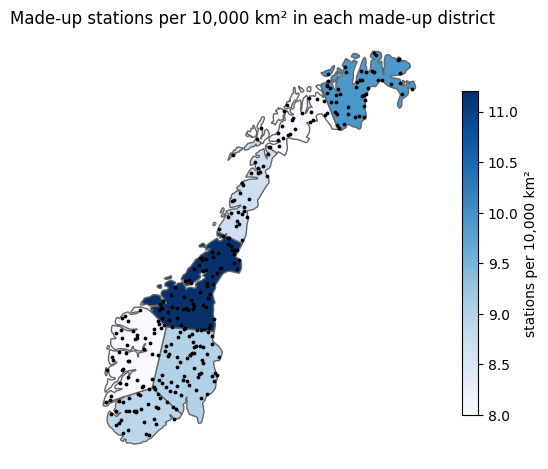

In [9]:
fig, ax = plt.subplots(figsize=(6, 7))
with_stations = per_district[per_district["stations"] > 0]
with_stations.plot(ax=ax, column="per_10000_km2", cmap="Blues", edgecolor="0.4", legend=True,
                   legend_kwds={"label": "stations per 10,000 km²", "shrink": 0.6})
stations_m.plot(ax=ax, color="black", markersize=3)
ax.set_xlim(-200_000, 1_200_000)
ax.set_ylim(6_400_000, 7_950_000)
ax.set_axis_off()
ax.set_title("Made-up stations per 10,000 km² in each made-up district")
plt.show()

The darkest district, Mid, is the one with the most stations for its size, and the palest, West and
Far North, have the fewest. The map leaves out Svalbard, which has no stations, so the color scale runs
over the seven districts that have them. `set_axis_off` hides the axes, whose numbers are meters in UTM
zone 33N and say nothing a reader of the map needs.

### Summarizing the stations in every district

The joined table is an ordinary DataFrame for `groupby`, so any summary of the stations' columns works
per district.

In [10]:
summary = joined.groupby("district").agg(
    stations=("station", "size"),
    mean_elevation_m=("elevation_m", "mean"),
    oldest=("installed", "min"),
).reindex(districts["district"])
summary.round(0)

,stations,mean_elevation_m,oldest
district,,,
South,32.0,333.0,1951.0
East,56.0,394.0,1950.0
West,43.0,350.0,1954.0
Mid,69.0,355.0,1950.0
North,27.0,375.0,1951.0
Far North,25.0,340.0,1952.0
Northeast,48.0,376.0,1952.0
Svalbard,NaN,NaN,NaN


East has the highest mean station elevation, 394 meters, and East and Mid hold the oldest stations,
from 1950. Svalbard's row is all `NaN`, because a mean or a minimum of no stations has no value. Only
`stations` has a natural 0, and the count above gave it one.

### Joining polygons to polygons

Which countries does each district lie in? A join with `intersects` gives an answer that is longer
than expected.

In [11]:
countries_m = countries.to_crs(districts.crs)
touching = gpd.sjoin(districts, countries_m[["ADMIN", "geometry"]])
print(len(touching), "rows")
touching.groupby("district", sort=False)["ADMIN"].apply(sorted)

15 rows


district
South                         [Norway]
East                  [Norway, Sweden]
West                          [Norway]
Mid                   [Norway, Sweden]
North                 [Norway, Sweden]
Far North    [Finland, Norway, Sweden]
Northeast    [Finland, Norway, Russia]
Svalbard                      [Norway]
Name: ADMIN, dtype: object

The eight districts make 15 rows, and five districts appear to lie partly in Sweden, Finland or
Russia. Measuring the area each pair shares shows why.

In [12]:
shared = [district.intersection(countries_m.loc[label, "geometry"]).area / 1e6
          for district, label in zip(touching.geometry, touching["index_right"])]
shared_pairs = touching.assign(shared_km2=np.round(shared, 1))
shared_pairs.sort_values(["district", "ADMIN"])[["district", "ADMIN", "shared_km2"]]

,district,ADMIN,shared_km2
1,East,Norway,62504.0
1,East,Sweden,0.0
5,Far North,Finland,0.0
5,Far North,Norway,31283.2
5,Far North,Sweden,0.0
3,Mid,Norway,61575.2
3,Mid,Sweden,0.0
4,North,Norway,30983.9
4,North,Sweden,0.0
6,Northeast,Finland,0.0


Every district shares thousands of square kilometers with Norway and 0.0 with any other country. The
districts were cut from Norway's outline, so their outer edges run along the border, and two shapes
that share an edge intersect along it. For East and Mid, GEOS also finds specks of shared area with
Sweden, far too small to show at one decimal place, so the extra pairs are a mix of shared edges and
specks, and a threshold on the shared area handles both.

In [13]:
shared_pairs[shared_pairs["shared_km2"] > 1][["district", "ADMIN", "shared_km2"]]

,district,ADMIN,shared_km2
0,South,Norway,36055.8
1,East,Norway,62504.0
2,West,Norway,53903.8
3,Mid,Norway,61575.2
4,North,Norway,30983.9
5,Far North,Norway,31283.2
6,Northeast,Norway,48523.0
7,Svalbard,Norway,62067.9


Keeping only the pairs that share more than 1 km² leaves one country, Norway, for every district. The
**Buffers, Overlays and Clipping** notebook cuts one layer's polygons by another's with `overlay`,
which returns the shared pieces themselves.

## Your turn

Five tasks. Write your answer in the cell under each task and run it.

Try a task before you look at its answer. Reading a solution teaches you much less than
getting there yourself, even slowly.

When you are ready: [**open the solutions notebook**](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/08-spatial-joins-solutions.ipynb).

**1.** Join the network stations to the districts and print how many stations each `owner` has in the North district.

In [14]:
# your code here

**2.** Print every district's count of stations installed in 2000 or later, with Svalbard shown as 0.

In [15]:
# your code here

**3.** Join the five named stations to `countries` with a left join, and print each station's country, with `NaN` where it has none.

In [16]:
# your code here

**4.** Add a column `airport_share` to a copy of the districts, the share of each district's stations whose owner is `airport`, with Svalbard left as `NaN`, and print it rounded to two places.

In [17]:
# your code here

**5.** Draw a map of the districts colored by their mean station elevation, with the stations on top.

In [18]:
# your code here

## Common errors

### `UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.`

The stations are joined in degrees to the districts in meters.

In [19]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", UserWarning)
    mismatched = gpd.sjoin(stations, districts)
for warning in caught:
    lines = str(warning.message).splitlines()
    print(f"{warning.category.__name__}: {lines[0]}")
    for line in lines[-2:]:
        print(line)
print("rows:", len(mismatched))

Left CRS: EPSG:4326
Right CRS: EPSG:25833
rows: 0


The warning's last lines name both CRSs, EPSG:4326 and EPSG:25833. The join still runs on the
numbers. A station's longitude and latitude are both below 100, and every district's northing is above
6,400,000 meters, so nothing matches. Convert one table to the other's
CRS before the join, as `stations_m` does.

### `ValueError: 'index_right' cannot be a column name in the frames being joined`

A table that came out of one join is joined again, to the countries.

In [20]:
first = gpd.sjoin(stations.to_crs(districts.crs), districts)
gpd.sjoin(first, countries.to_crs(districts.crs)[["ADMIN", "geometry"]])

ValueError: 'index_right' cannot be a column name in the frames being joined

The second join would add its own `index_right`, and the first join's column already has that name.
Drop or rename the old column before joining again.

In [21]:
again = gpd.sjoin(first.drop(columns="index_right"), countries.to_crs(districts.crs)[["ADMIN", "geometry"]])
again[["station", "district", "ADMIN"]].head(3)

,station,district,ADMIN
0,NS001,East,Norway
1,NS002,Mid,Norway
2,NS003,Northeast,Norway


### No error, and Svalbard missing from the count

In [22]:
inner = gpd.sjoin(stations.to_crs(districts.crs), districts)
inner.groupby("district").size()

district
East         56
Far North    25
Mid          69
North        27
Northeast    48
South        32
West         43
dtype: int64

The count has seven districts. An inner join has no row for a district without stations, and
`groupby` counts only the rows it has, so Svalbard is not in the result, and the districts come out in
alphabetical order. Reindex to the districts with `fill_value=0`, as the worked examples did, or start
from a right join.

### ``ValueError: `how` was "outer" but is expected to be in ['left', 'right', 'inner']``

A `merge` takes `how="outer"`, which keeps unmatched rows from both sides.

In [23]:
gpd.sjoin(stations.to_crs(districts.crs), districts, how="outer")

ValueError: `how` was "outer" but is expected to be in ['left', 'right', 'inner']

`sjoin` accepts three kinds of join, and the message lists them. To keep every station, use a left
join, and to keep every district, a right join, as the worked examples showed.

## Recap

- You can join points to polygons with `sjoin`, in one CRS, and read `index_right` and the suffixes
  it adds.
- You can choose a predicate, and read it as `left.predicate(right)`.
- You can choose between inner, left and right joins by which rows the answer must keep.
- You can count and summarize the points in every polygon, with empty polygons kept.
- You can join polygons to polygons and keep only the pairs that share a real area.

## What is next

The **Nearest Neighbors** notebook joins each row to the closest shape in another table, with the
distance between them, which matches Tromso and Kirkenes to the land they stand beside.

---

&#8592; **Previous:** [Spatial Predicates](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/07-spatial-predicates.ipynb)  &nbsp;·&nbsp;  [GeoPandas, Deep Dive Notebooks](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)  &nbsp;·&nbsp;  **Next:** [Nearest Neighbors](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/09-nearest-neighbors.ipynb) &#8594;
